In [1]:
using Glob
using CommonDataFormat
using Dates
using Statistics
using CairoMakie
include("../../src/scripts/MAVEN_load.jl")
include("../../src/scripts/MAVEN_plot.jl")
using .MAVEN_load
using .MAVEN_plot

date = Date(2022, 8, 24)
datestr = Dates.format.(date, "yyyymmdd")
year_num = Dates.format(date, "yyyy")
month_num = Dates.format(date, "mm")

data_dir = "E:\\Data"
output_dir = "E:\\Output"
MAVEN_path = joinpath(data_dir, "MAVEN")
STATIC_path = joinpath(MAVEN_path, "STATIC", "l2", year_num, month_num)
MAVEN_output_path = joinpath(output_dir, "MAVEN")
STATIC_output_path = joinpath(MAVEN_output_path, "STATIC")
fluxmean_path = joinpath(STATIC_output_path, "fluxmean", year_num, month_num)
mkpath(fluxmean_path)

STA_file = glob("mvn_sta_l2*32e4d16a8m*$datestr*.cdf", STATIC_path)
println("STATIC file: ", STA_file)
println("Output path: ", fluxmean_path)

sta_data = MAVEN_load.load_STATIC(STA_file[1])

STATIC file: ["E:\\Data\\MAVEN\\STATIC\\l2\\2022\\08\\mvn_sta_l2_d0-32e4d16a8m_20220824_v02_r07.cdf"]
Output path: E:\Output\MAVEN\STATIC\fluxmean\2022\08


Dict{Symbol, Any} with 16 entries:
  :denergy   => Float32[6.61989 6.61989 … 6.61989 6.61989; 6.61989 6.61989 … 6.…
  :mode      => Int16[4, 4, 4, 4, 4, 4, 4, 4, 4, 4  …  4, 4, 4, 4, 4, 4, 4, 4, …
  :quat_mso  => Float32[0.791865 -0.610687 0.00269 0.00224343; 0.792456 -0.6099…
  :swp_ind   => Int16[25, 25, 25, 25, 25, 25, 25, 25, 25, 25  …  25, 25, 25, 25…
  :JulUTtime => [2.45982e6, 2.45982e6, 2.45982e6, 2.45982e6, 2.45982e6, 2.45982…
  :quat_sc   => Float32[0.501247 -0.502145 -0.497111 -0.499482; 0.501247 -0.502…
  :dphi      => Float32[22.5 22.5 … 22.5 22.5; 22.5 22.5 … 22.5 22.5; … ; 22.5 …
  :mass      => Float32[0.515882 0.515882 … 0.515882 0.515882; 2.4772 2.4772 … …
  :domega    => Float32[0.157183 0.157183 … 0.157183 0.157183; 0.157183 0.15718…
  :energy    => Float32[50.5891 50.5891 … 50.5891 50.5891; 50.5891 50.5891 … 50…
  :eflux     => Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0…
  :dtheta    => Float32[22.9333 22.9333 … 22.9333 22.9333; 22.9333 22.9333

In [9]:
sta_data[:eflux]

2700×8×64×32 Array{Float32, 4}:
[:, :, 1, 1] =
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 ⋮                        ⋮         
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  

In [49]:
img = 1
time_range = DateTime(date, Time(7, 00, 00)).+Dates.Minute(1) .* range(0, 1)
idx = findall(time_range[1] .<= sta_data[:epoch] .<= time_range[end])
swp = sta_data[:swp_ind][idx[1]]
energy = sta_data[:energy][img,:,:,swp][1,:]
phi = sta_data[:phi][img,:,:,swp]
theta = sta_data[:theta][img,:,:,swp]
flux = sta_data[:eflux][idx, img, :,:]
fluxmean = dropdims(mean(flux, dims=(1)), dims=(1))
fluxmean_phi = dropdims(mean(reshape(fluxmean, 4, 16, 32), dims=1), dims=1)
fluxmean_theta = [mean(fluxmean[i:4:end, j]) for i in 1:4, j in 1:32]

4×32 Matrix{Float32}:
 0.0  0.0  0.0  10454.5   38822.1  …     0.0   0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0   9427.58  46164.9        0.0   0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0      0.0   10657.5     3983.42  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0      0.0       0.0     4752.9   0.0  0.0  0.0  0.0  0.0

┌ Warning: Found `resolution` in the theme when creating a `Scene`. The `resolution` keyword for `Scene`s and `Figure`s has been deprecated. Use `Figure(; size = ...` or `Scene(; size = ...)` instead, which better reflects that this is a unitless size and not a pixel resolution. The key could also come from `set_theme!` calls or related theming functions.
└ @ Makie C:\Users\USTC\.julia\packages\Makie\Vn16E\src\scenes.jl:264


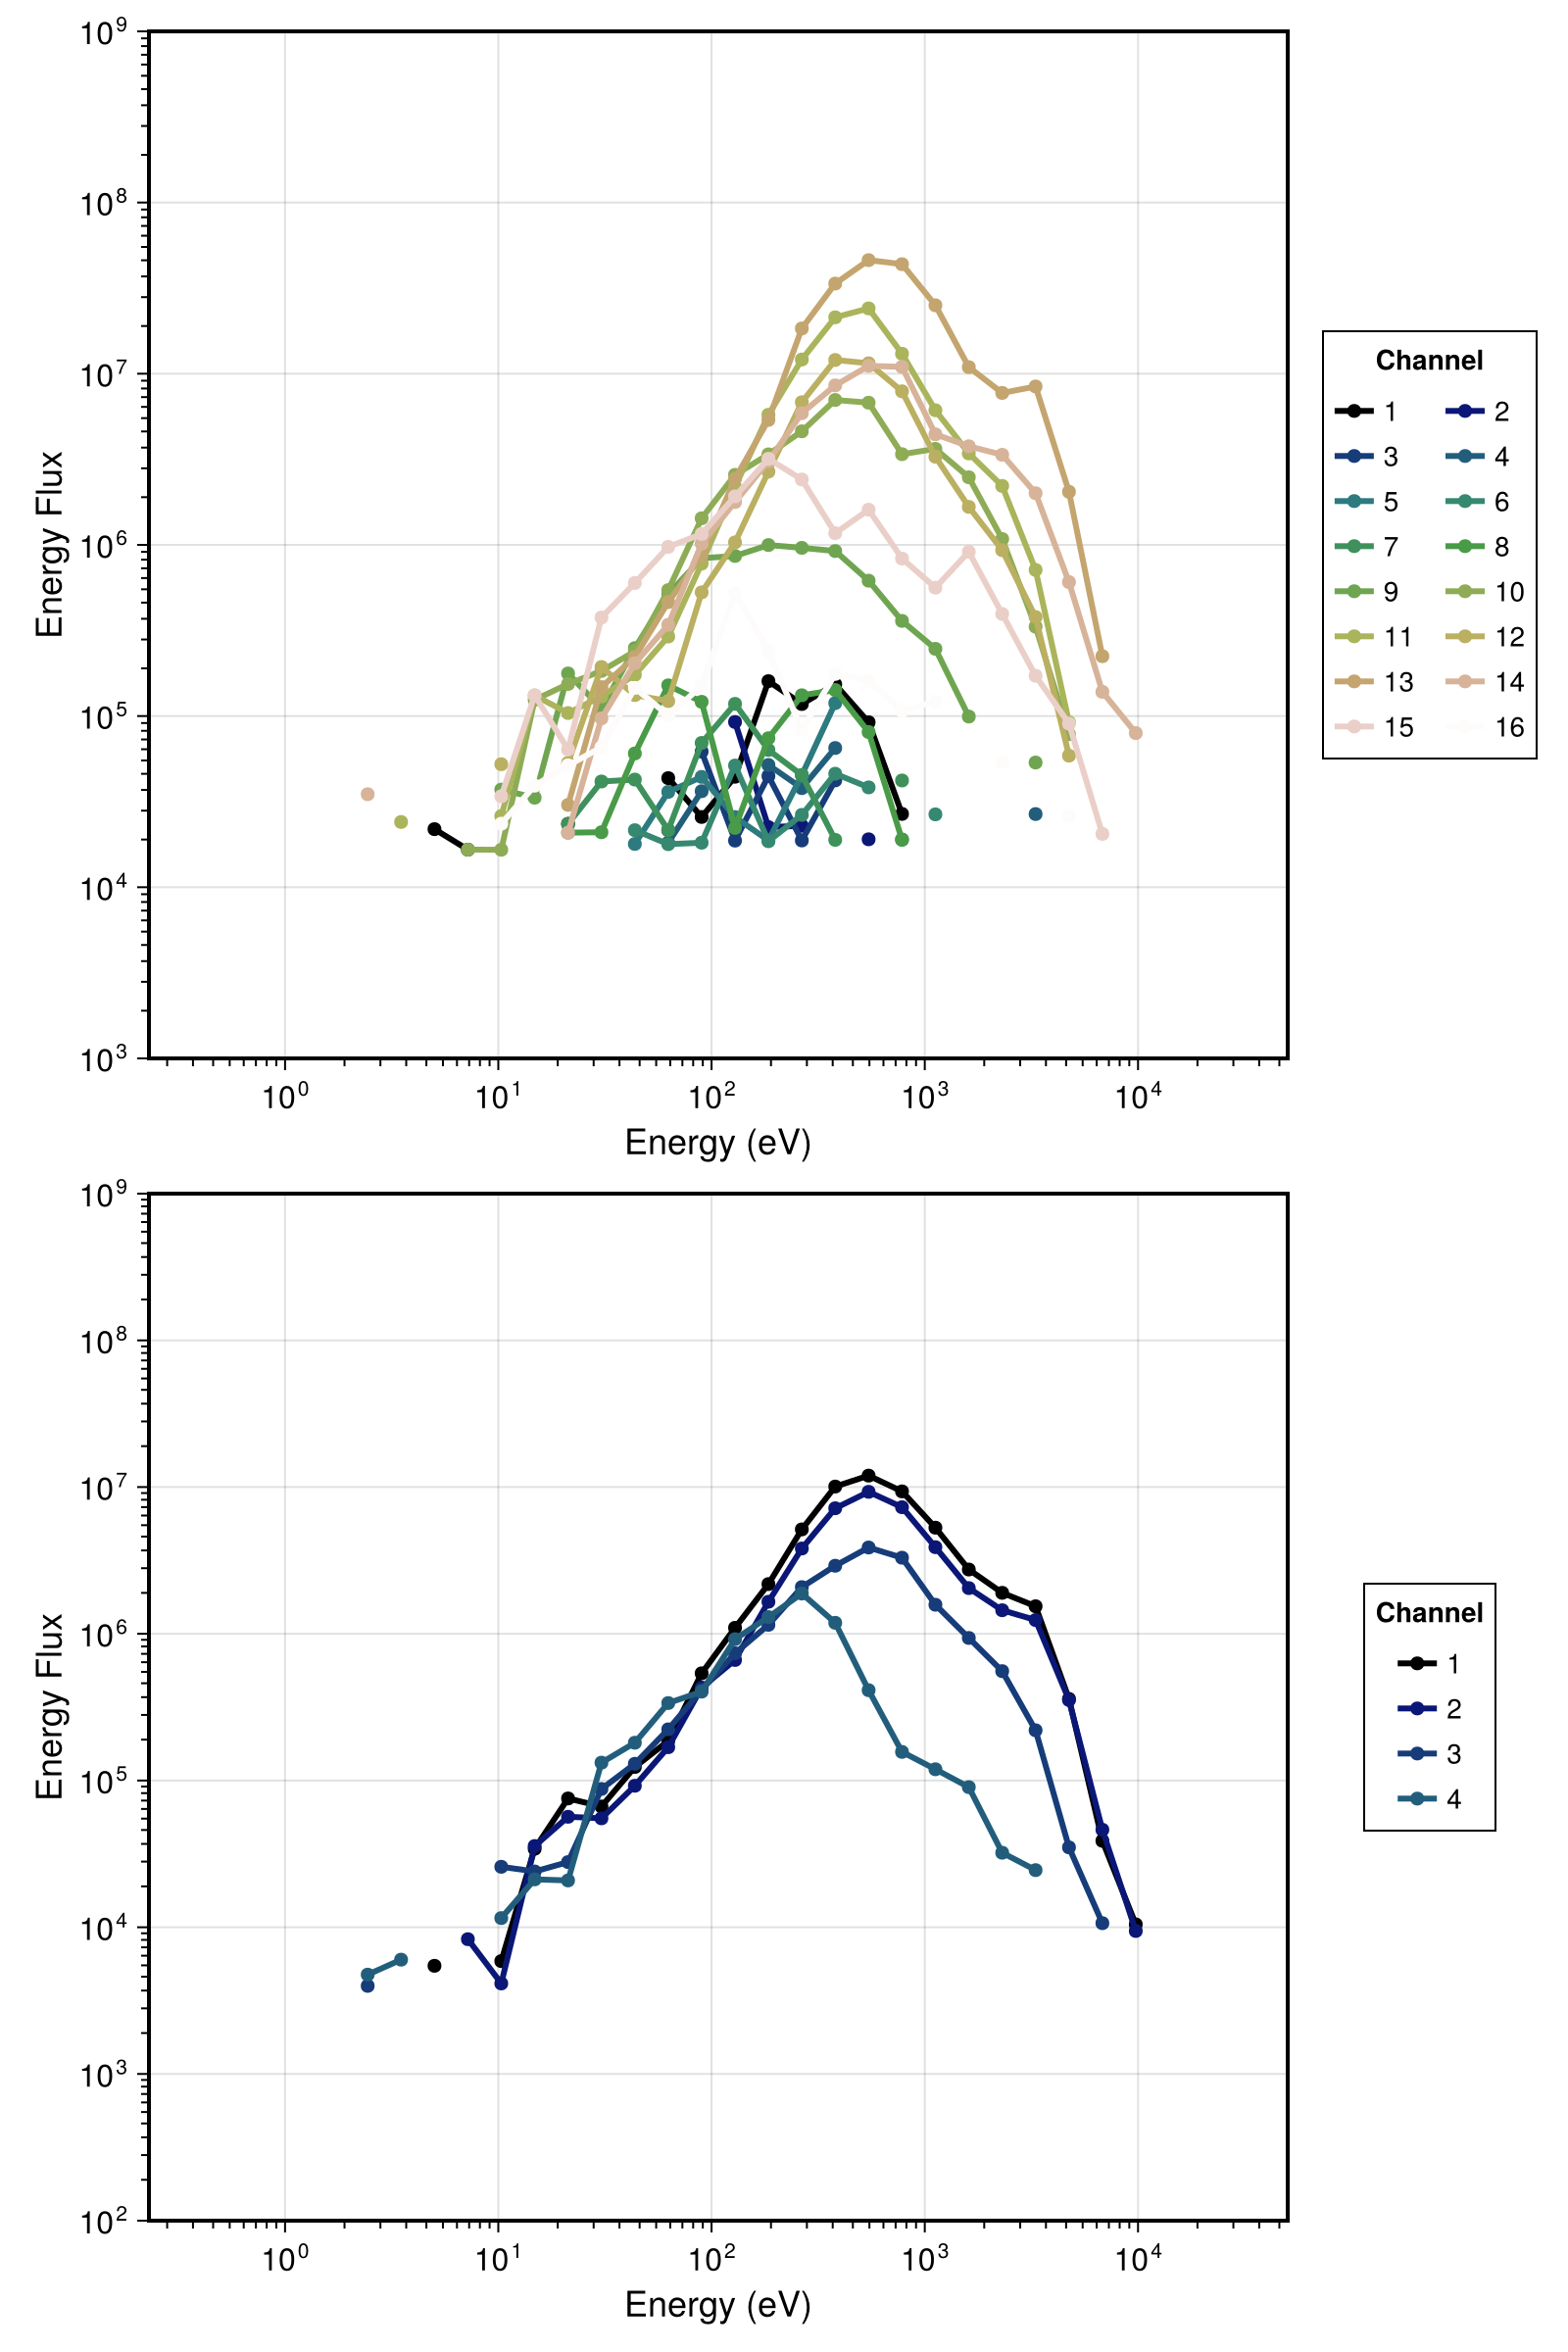

CairoMakie.Screen{IMAGE}


In [51]:
using CairoMakie
CairoMakie.activate!()
set_theme!(;
    Axis=(xscale = log10, yscale = log10,
        bordercolor=:black, bordersize=15, spinewidth = 2, 
        xlabelsize=18, ylabelsize=18, xticklabelsize=16, yticklabelsize=16, 
        xminorticksvisible = true, yminorticksvisible = true,
        xminorticks = IntervalsBetween(10), yminorticks = IntervalsBetween(10))
)
fig = Figure(resolution = (800, 1200))
ax1 = Axis(fig[1, 1];xlabel="Energy (eV)" ,ylabel="Energy Flux")
ax2 = Axis(fig[2, 1];xlabel="Energy (eV)" ,ylabel="Energy Flux")
colors = cgrad(:gist_earth, 16, categorical = true)
ylims!(ax1, 1e3, 1e9)
for i in 1:16
scatterlines!(ax1, energy, fluxmean_phi[i, :], color = colors[i], label = "$i", 
    linewidth = 3, marker = :circle, markersize = 10)
end
# 添加图例
Legend(fig[1, 2], ax1, "Channel", nbanks = 2)
# --- 绘制下图 (示例：只选前 4 个通道) ---
ylims!(ax2, 1e2, 1e9)
for i in 1:4
scatterlines!(ax2, energy, fluxmean_theta[i, :], color = colors[i], label = "$i", 
    linewidth = 3, marker = :circle, markersize = 10)
end
Legend(fig[2, 2], ax2, "Channel")
display(fig)

In [25]:
fluxmean_phi = dropdims(mean(reshape(fluxmean, 4, 16, 32), dims=1), dims=1)

16×32 Matrix{Float32}:
 0.0     0.0  0.0   1478.47   21518.7   …     0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0    46041.5         0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0        0.0         0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0     2714.55        0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0     1470.76        0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0     6866.18  …     0.0    976.919  0.0  0.0
 0.0     0.0  0.0   9948.53   40211.3         0.0      0.0    0.0  0.0
 0.0     0.0  0.0  27142.8    22032.4         0.0   1410.49   0.0  0.0
 0.0  1456.5  0.0   3780.72  251016.0         0.0      0.0    0.0  0.0
 0.0     0.0  0.0   4838.54   10425.6         0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0        0.0   …     0.0   1229.63   0.0  0.0
 0.0     0.0  0.0      0.0        0.0         0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0        0.0         0.0      0.0    0.0  0.0
 0.0     0.0  0.0      0.0    40441.2         0.0     

In [30]:
fluxmean_theta = [mean(fluxmean[i:4:end, :]) for i in 1:4, j in 1:32]

4×32 Matrix{Float32}:
 89404.7        89404.7        89404.7        …  89404.7        89404.7
     1.52971f6      1.52971f6      1.52971f6         1.52971f6      1.52971f6
     9.92337f5      9.92337f5      9.92337f5         9.92337f5      9.92337f5
     1.18004f5      1.18004f5      1.18004f5         1.18004f5      1.18004f5

In [23]:
energy

32-element Vector{Float32}:
 28791.484
 20075.168
 13997.621
  9759.989
  6805.2554
  4745.036
  3308.5264
  2306.905
  1608.5139
  1121.5532
   782.0149
   545.2681
   380.19397
     ⋮
    21.24056
    14.810205
    10.3265705
     7.2003107
     5.0204926
     3.5005915
     2.4408245
     1.7018905
     1.1866612
     0.827412
     0.57692176
     0.40226477

In [19]:
phi

64×32 Matrix{Float32}:
 -157.5  -157.5  -157.5  -157.5  -157.5  …  -157.5  -157.5  -157.5  -157.5
 -157.5  -157.5  -157.5  -157.5  -157.5     -157.5  -157.5  -157.5  -157.5
 -157.5  -157.5  -157.5  -157.5  -157.5     -157.5  -157.5  -157.5  -157.5
 -157.5  -157.5  -157.5  -157.5  -157.5     -157.5  -157.5  -157.5  -157.5
 -135.0  -135.0  -135.0  -135.0  -135.0     -135.0  -135.0  -135.0  -135.0
 -135.0  -135.0  -135.0  -135.0  -135.0  …  -135.0  -135.0  -135.0  -135.0
 -135.0  -135.0  -135.0  -135.0  -135.0     -135.0  -135.0  -135.0  -135.0
 -135.0  -135.0  -135.0  -135.0  -135.0     -135.0  -135.0  -135.0  -135.0
 -112.5  -112.5  -112.5  -112.5  -112.5     -112.5  -112.5  -112.5  -112.5
 -112.5  -112.5  -112.5  -112.5  -112.5     -112.5  -112.5  -112.5  -112.5
 -112.5  -112.5  -112.5  -112.5  -112.5  …  -112.5  -112.5  -112.5  -112.5
 -112.5  -112.5  -112.5  -112.5  -112.5     -112.5  -112.5  -112.5  -112.5
  -90.0   -90.0   -90.0   -90.0   -90.0      -90.0   -90.0   -90.0   -90.0
  

In [20]:
theta

64×32 Matrix{Float32}:
  6.14222   8.80907   12.6338    18.1192   …   34.4      34.4      34.4
  2.04741   2.93636    4.21128    6.03975      11.4667   11.4667   11.4667
 -2.04741  -2.93636   -4.21128   -6.03975     -11.4667  -11.4667  -11.4667
 -6.14222  -8.80907  -12.6338   -18.1192      -34.4     -34.4     -34.4
  6.14222   8.80907   12.6338    18.1192       34.4      34.4      34.4
  2.04741   2.93636    4.21128    6.03975  …   11.4667   11.4667   11.4667
 -2.04741  -2.93636   -4.21128   -6.03975     -11.4667  -11.4667  -11.4667
 -6.14222  -8.80907  -12.6338   -18.1192      -34.4     -34.4     -34.4
  6.14222   8.80907   12.6338    18.1192       34.4      34.4      34.4
  2.04741   2.93636    4.21128    6.03975      11.4667   11.4667   11.4667
 -2.04741  -2.93636   -4.21128   -6.03975  …  -11.4667  -11.4667  -11.4667
 -6.14222  -8.80907  -12.6338   -18.1192      -34.4     -34.4     -34.4
  6.14222   8.80907   12.6338    18.1192       34.4      34.4      34.4
  ⋮                    

In [ ]:
using Glob
using CommonDataFormat
using Dates
using Statistics
using CairoMakie
include("../../src/scripts/MAVEN_load.jl")
include("../../src/scripts/MAVEN_plot.jl")
include("../../src/scripts/MAVEN_STATIC.jl")
using .MAVEN_load
using .MAVEN_plot
using .MAVEN_STATIC

date = Date(2022, 8, 24)
datestr = Dates.format.(date, "yyyymmdd")
year_num = Dates.format(date, "yyyy")
month_num = Dates.format(date, "mm")

data_dir = "E:\\Data"
output_dir = "E:\\Output"
MAVEN_path = joinpath(data_dir, "MAVEN")
MAG_path = joinpath(MAVEN_path, "MAG", "l2", year_num, month_num)
STATIC_path = joinpath(MAVEN_path, "STATIC", "l2", year_num, month_num)
MAVEN_output_path = joinpath(output_dir, "MAVEN")
STATIC_output_path = joinpath(MAVEN_output_path, "STATIC")
VDF_path = joinpath(STATIC_output_path, "VDF", year_num, month_num)
mkpath(VDF_path)
MAG_file = glob("mvn_mag_l2*$datestr*.sts", MAG_path)
STA_file = glob("mvn_sta_l2*32e4d16a8m*$datestr*.cdf", STATIC_path)
println("MAG file: ", MAG_file)
println("STATIC file: ", STA_file)
println("Output path: ", VDF_path)

mag_data = MAVEN_load.load_mag_l2(MAG_file[1])
sta_data = MAVEN_load.load_STATIC(STA_file[1])
println("Data loaded.")

In [ ]:
spice = Dict(
    :mass_range => [0, 2],
    :m_int => 1,
)
ion_vel = 160.0
spice_name = "H+"
colorrange = (1e-13, 1e-10)
V_30ev = MAVEN_STATIC.ion_energy2v(30, spice[:m_int]) / 1000
V_494ev = MAVEN_STATIC.ion_energy2v(494, spice[:m_int]) / 1000